
# Global Retail Outlet Mapping & Intelligence

## Project Overview

This project focuses on collecting, extracting, cleaning, and analyzing retail outlet data across Abuja, Nigeria, using Python-based web scraping and data extraction techniques.

## Project Objectives

1. Collect retail outlet information from online sources.
2. Extract business names, categories, addresses, and geographical coordinates.
3. Clean and validate the extracted data.
4. Identify duplicate and missing records.
5. Analyze the geographical distribution of retail outlets.

## Tools and Technologies

- Python
- Requests
- BeautifulSoup
- Pandas
- Jupyter Notebook
- OpenStreetMap API

## Data Sources

- OpenStreetMap
- Public business directories



## 2. Importing Libraries

In this section, we import the Python libraries required for data collection, extraction, manipulation, and analysis.

The libraries will help us communicate with web APIs, process structured data, and inspect the collected information.


In [1]:

# Importing required libraries

import requests
import pandas as pd
import json
import time



## 3. Data Source Understanding

### OpenStreetMap (OSM)

OpenStreetMap is the primary geographical data source for this project. It provides information about geographical locations and points of interest, including retail businesses.

### Overpass API

The Overpass API allows us to retrieve specific geographical data from OpenStreetMap using structured queries.

### Data Collection Approach

We will use Python Requests to communicate with the Overpass API and retrieve business information in JSON format.

The retrieved data will subsequently be transformed into a structured Pandas DataFrame for inspection and cleaning.


## 4. Data Extraction Using Overpass API

We use the Overpass API to programmatically retrieve retail and business location data from OpenStreetMap.

Python's Requests library sends our query to the API, while the returned JSON response contains the raw business records.

In [2]:
# Define the Overpass API endpoint

overpass_url = "https://overpass-api.de/api/interpreter"

In [3]:
# Define the Overpass query

query = """
[out:json][timeout:120];

(
  nwr["shop"](8.8,7.2,9.2,7.6);
  nwr["amenity"~"^(pharmacy|restaurant|cafe|fast_food)$"](8.8,7.2,9.2,7.6);
);

out center;
"""

In [4]:
# Send the query to the Overpass API

response = requests.get(
    overpass_url,
    params={"data": query},
    timeout=180
)

print(response.status_code)

406


In [5]:
# Add a User-Agent header

headers = {
    "User-Agent": "GlobalRetailMappingProject/1.0 (Python data collection)"
}

response = requests.get(
    overpass_url,
    params={"data": query},
    headers=headers,
    timeout=180
)

print("Status Code:", response.status_code)
print("Response:", response.text[:500])

Status Code: 200
Response: {
  "version": 0.6,
  "generator": "Overpass API 0.7.62.11 87bfad18",
  "osm3s": {
    "timestamp_osm_base": "2026-11-11T09:21:47Z",
    "copyright": "The data included in this document is from www.openstreetmap.org. The data is made available under ODbL."
  },
  "elements": [

{
  "type": "node",
  "id": 31445570,
  "lat": 9.0327607,
  "lon": 7.4430199,
  "tags": {
    "name": "Millipat Plaza",
    "note": "indoor_shopping_centre",
    "shop": "mall"
  }
},
{
  "type": "node",
  "id": 31450344,


In [6]:
# Convert the API response into JSON

data = response.json()

# Check the structure of the returned data

print(data.keys())

dict_keys(['version', 'generator', 'osm3s', 'elements'])


In [7]:
# Extract the business records

elements = data["elements"]

# Count the total records

print("Total records collected:", len(elements))

Total records collected: 433


In [8]:
# Display the first business record

elements[0]

{'type': 'node',
 'id': 31445570,
 'lat': 9.0327607,
 'lon': 7.4430199,
 'tags': {'name': 'Millipat Plaza',
  'note': 'indoor_shopping_centre',
  'shop': 'mall'}}

In [9]:
# Inspect the business tags

elements[0]["tags"]

{'name': 'Millipat Plaza', 'note': 'indoor_shopping_centre', 'shop': 'mall'}

In [10]:
# Check the available tags in another record

elements[10]["tags"]

{'name': 'shoplifter apo', 'shop': 'convenience'}

In [11]:
# Collect all unique tag names across the dataset

all_tags = set()

for element in elements:
    tags = element.get("tags", {})
    all_tags.update(tags.keys())

print("Available tags:")
print(sorted(all_tags))

Available tags:
['addr:block', 'addr:city', 'addr:district', 'addr:housename', 'addr:housenumber', 'addr:neighbourhood', 'addr:plot', 'addr:postcode', 'addr:street', 'addr:suite', 'addr:unit', 'air_conditioning', 'alt_name', 'alt_name:en', 'amenity', 'baby_feeding', 'bar', 'beauty', 'beds', 'branch', 'brand', 'brand:email', 'brand:website', 'brand:wikidata', 'brand:wikipedia', 'building', 'building:levels', 'building:material', 'building:use', 'changing_table', 'check_date', 'check_date:currency:XBT', 'check_date:opening_hours', 'clothes', 'contact:email', 'contact:facebook', 'contact:instagram', 'contact:phone', 'contact:website', 'contact:whatsapp', 'craft', 'cuisine', 'currency:EUR', 'currency:NGN', 'currency:USD', 'currency:XBT', 'currency:others', 'delivery', 'description', 'diet:dairy', 'diet:dairy_free', 'diet:diabetes', 'diet:egg_free', 'diet:fish', 'diet:fruitarian', 'diet:gluten_free', 'diet:halal', 'diet:local', 'diet:meat', 'diet:sugar_free', 'diet:vegetarian', 'dispensing'

## 5. Data Availability Assessment

Not all businesses in OpenStreetMap have complete information. Before extracting our dataset, we assess the availability of important fields.

This helps us understand data completeness and identify fields that may require special attention during cleaning.

In [12]:
# Define the important fields we want to investigate

important_fields = [
    "name",
    "shop",
    "amenity",
    "phone",
    "contact:phone",
    "website",
    "contact:website",
    "opening_hours",
    "addr:street",
    "addr:city"
]

# Count records containing each field

for field in important_fields:
    count = sum(
        1 for element in elements
        if element.get("tags", {}).get(field)
    )

    percentage = (count / len(elements)) * 100

    print(f"{field}: {count} records ({percentage:.1f}%)")

name: 328 records (75.8%)
shop: 273 records (63.0%)
amenity: 166 records (38.3%)
phone: 70 records (16.2%)
contact:phone: 14 records (3.2%)
website: 41 records (9.5%)
contact:website: 1 records (0.2%)
opening_hours: 79 records (18.2%)
addr:street: 117 records (27.0%)
addr:city: 78 records (18.0%)


In [13]:
# Create a data availability summary

availability_data = []

for field in important_fields:
    count = sum(
        1 for element in elements
        if element.get("tags", {}).get(field)
    )

    percentage = (count / len(elements)) * 100

    availability_data.append({
        "Field": field,
        "Available Records": count,
        "Missing Records": len(elements) - count,
        "Coverage (%)": round(percentage, 2)
    })

availability_df = pd.DataFrame(availability_data)

availability_df

,Field,Available Records,Missing Records,Coverage (%)
0,name,328,105,75.75
1,shop,273,160,63.05
2,amenity,166,267,38.34
3,phone,70,363,16.17
4,contact:phone,14,419,3.23
5,website,41,392,9.47
6,contact:website,1,432,0.23
7,opening_hours,79,354,18.24
8,addr:street,117,316,27.02
9,addr:city,78,355,18.01


## 6. Data Completeness Visualization

A horizontal bar chart is used to compare the availability of important business attributes across the collected records.

This visualization helps identify fields with high and low data coverage and highlights potential data quality limitations.

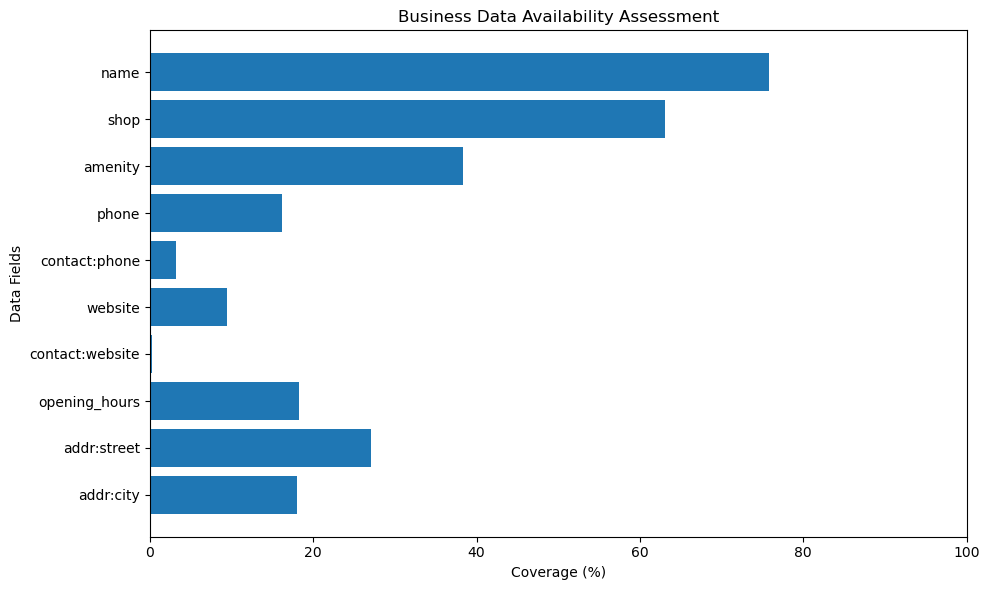

In [14]:
# Visualize data coverage

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    availability_df["Field"],
    availability_df["Coverage (%)"]
)

plt.xlabel("Coverage (%)")
plt.ylabel("Data Fields")
plt.title("Business Data Availability Assessment")
plt.xlim(0, 100)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 7. Structured Data Extraction

The raw data retrieved from OpenStreetMap is stored in nested JSON format.

In this stage, we extract relevant business attributes and transform them into a tabular structure using Pandas.

Each row will represent a business location, while each column will contain a specific attribute.

In [15]:
# Extract relevant business attributes from the JSON records

business_records = []

for element in elements:

    tags = element.get("tags", {})

    record = {
        "OSM_ID": element.get("id"),
        "Object_Type": element.get("type"),
        "Business_Name": tags.get("name"),
        "Brand": tags.get("brand"),
        "Shop_Category": tags.get("shop"),
        "Amenity_Category": tags.get("amenity"),
        "Phone": tags.get("phone") or tags.get("contact:phone"),
        "Email": tags.get("email") or tags.get("contact:email"),
        "Website": tags.get("website") or tags.get("contact:website"),
        "Opening_Hours": tags.get("opening_hours"),
        "Street": tags.get("addr:street"),
        "City": tags.get("addr:city"),
        "Postcode": tags.get("addr:postcode"),
        "Latitude": element.get("lat") or element.get("center", {}).get("lat"),
        "Longitude": element.get("lon") or element.get("center", {}).get("lon")
    }

    business_records.append(record)

# Convert extracted records into a DataFrame

df = pd.DataFrame(business_records)

df.head()

,OSM_ID,Object_Type,Business_Name,Brand,Shop_Category,Amenity_Category,Phone,Email,Website,Opening_Hours,Street,City,Postcode,Latitude,Longitude
0,31445570,node,Millipat Plaza,None,mall,None,None,None,None,None,None,None,None,9.032761,7.443020
1,31450344,node,Fish,None,None,restaurant,None,None,None,None,None,None,None,9.047269,7.536203
2,541871957,node,Manan,None,supermarket,None,None,None,None,None,None,None,None,9.040524,7.525267
3,560983277,node,Bukkateen,None,None,restaurant,None,None,None,None,None,None,None,9.040562,7.465440
4,889008138,node,Mr Biggs,None,None,fast_food,None,None,None,None,None,None,None,9.061920,7.417699


In [16]:
# Inspect the original record for Mr Biggs

elements[4]

{'type': 'node',
 'id': 889008138,
 'lat': 9.0619204,
 'lon': 7.4176986,
 'tags': {'amenity': 'fast_food', 'name': 'Mr Biggs'}}

In [17]:
# Check the extracted coordinates

df.loc[4, ["Business_Name", "Latitude", "Longitude"]]

Business_Name    Mr Biggs
Latitude          9.06192
Longitude        7.417699
Name: 4, dtype: object

## 8. Initial Data Quality Assessment

After extracting the business attributes, we examine the dataset for missing values and duplicate records.

This assessment helps identify inconsistencies and potential issues that need to be addressed before analysis.

In [18]:
# Check missing values in each column

df.isnull().sum()

OSM_ID                0
Object_Type           0
Business_Name       105
Brand               387
Shop_Category       160
Amenity_Category    267
Phone               349
Email               398
Website             391
Opening_Hours       354
Street              316
City                355
Postcode            387
Latitude              0
Longitude             0
dtype: int64

In [19]:
# Check the overall dataset structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 433 entries, 0 to 432
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   OSM_ID            433 non-null    int64  
 1   Object_Type       433 non-null    object 
 2   Business_Name     328 non-null    object 
 3   Brand             46 non-null     object 
 4   Shop_Category     273 non-null    object 
 5   Amenity_Category  166 non-null    object 
 6   Phone             84 non-null     object 
 7   Email             35 non-null     object 
 8   Website           42 non-null     object 
 9   Opening_Hours     79 non-null     object 
 10  Street            117 non-null    object 
 11  City              78 non-null     object 
 12  Postcode          46 non-null     object 
 13  Latitude          433 non-null    float64
 14  Longitude         433 non-null    float64
dtypes: float64(2), int64(1), object(12)
memory usage: 50.9+ KB


In [20]:
# Check for duplicate OSM IDs

duplicate_count = df.duplicated(subset=["OSM_ID"]).sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [21]:
# Check for duplicate business names

duplicate_names = df[
    df["Business_Name"].notna() &
    df["Business_Name"].duplicated(keep=False)
].sort_values("Business_Name")

print("Records with duplicate business names:", len(duplicate_names))

duplicate_names[
    ["OSM_ID", "Business_Name", "Shop_Category", "Amenity_Category"]
]

Records with duplicate business names: 50


,OSM_ID,Business_Name,Shop_Category,Amenity_Category
326,881248855,Bites & Grills,None,restaurant
61,8196228181,Bites & Grills,None,fast_food
59,8196228179,Bites & Grills,None,restaurant
425,1411662859,Chicken Republic,None,fast_food
203,11922113362,Chicken Republic,None,fast_food
318,776646819,Chicken Republic,None,fast_food
253,12984921096,Domino's,None,fast_food
186,11659559413,Domino's,None,fast_food
413,1283367530,H-Medix,mall,None
323,780720767,H-Medix,supermarket,None


In [22]:
# Count the frequency of each repeated business name

duplicate_name_counts = (
    duplicate_names["Business_Name"]
    .value_counts()
    .reset_index()
)

duplicate_name_counts.columns = ["Business_Name", "Frequency"]

duplicate_name_counts

,Business_Name,Frequency
0,Miniso,4
1,Bites & Grills,3
2,Skylark Pharmacy,3
3,Skechers,3
4,Shoprite,3
5,Chicken Republic,3
6,Wuse Shopping Plaza,3
7,KFC,3
8,H-Medix,3
9,Market Square,2


In [23]:
# Inspect all Miniso records

df[df["Business_Name"] == "Miniso"][
    ["OSM_ID", "Business_Name", "Shop_Category",
     "Amenity_Category", "Latitude", "Longitude"]
]

,OSM_ID,Business_Name,Shop_Category,Amenity_Category,Latitude,Longitude
68,8341496209,Miniso,variety_store,None,9.067651,7.485528
225,12208663177,Miniso,variety_store,None,8.991049,7.393327
250,12911294443,Miniso,variety_store,None,8.990739,7.393439
255,12984921099,Miniso,variety_store,None,9.076041,7.425122


In [24]:
# Compare Miniso records with nearby coordinates

df.loc[[225, 250], [
    "OSM_ID",
    "Business_Name",
    "Latitude",
    "Longitude",
    "Street",
    "City"
]]

,OSM_ID,Business_Name,Latitude,Longitude,Street,City
225,12208663177,Miniso,8.991049,7.393327,None,None
250,12911294443,Miniso,8.990739,7.393439,None,None


In [25]:
# Inspect the original OpenStreetMap records

miniso_ids = [12208663177, 12911294443]

for element in elements:
    if element.get("id") in miniso_ids:
        print(element)
        print("-" * 50)

{'type': 'node', 'id': 12208663177, 'lat': 8.9910494, 'lon': 7.3933268, 'tags': {'brand': 'Miniso', 'name': 'Miniso', 'shop': 'variety_store'}}
--------------------------------------------------
{'type': 'node', 'id': 12911294443, 'lat': 8.9907391, 'lon': 7.3934391, 'tags': {'brand': 'Miniso', 'brand:wikidata': 'Q20732498', 'name': 'Miniso', 'shop': 'variety_store'}}
--------------------------------------------------


In [26]:
# Flag records with repeated business names

df["Duplicate_Name_Flag"] = (
    df["Business_Name"].notna() &
    df["Business_Name"].duplicated(keep=False)
)

# Count flagged records

print(df["Duplicate_Name_Flag"].value_counts())

Duplicate_Name_Flag
False    383
True      50
Name: count, dtype: int64


In [27]:
# Identify records without business names

missing_names = df[df["Business_Name"].isna()]

print("Records without business names:", len(missing_names))

missing_names[
    ["OSM_ID", "Object_Type", "Shop_Category",
     "Amenity_Category", "Latitude", "Longitude"]
].head(10)

Records without business names: 105


,OSM_ID,Object_Type,Shop_Category,Amenity_Category,Latitude,Longitude
6,893689255,node,electronics,None,9.068764,7.481996
7,1611132419,node,None,pharmacy,9.010886,7.575098
17,4239609894,node,None,pharmacy,9.065223,7.427674
20,4549849155,node,None,pharmacy,9.104024,7.492527
21,4549849156,node,None,pharmacy,9.077687,7.499636
64,8341496205,node,None,cafe,9.067597,7.485831
65,8341496206,node,None,cafe,9.067272,7.485687
66,8341496207,node,optician,None,9.067740,7.485616
96,9577867313,node,None,restaurant,9.079865,7.480993
103,9945426291,node,tailor,None,8.862447,7.423827


## 9. Category Standardization

Business categories in OpenStreetMap are stored under different tags, including shop and amenity.

To simplify analysis, we combine these attributes into a single Business_Category column while preserving the original classification columns.

In [28]:
# Combine shop and amenity categories

df["Business_Category"] = (
    df["Shop_Category"]
    .combine_first(df["Amenity_Category"])
)

# Check the new category column

df[[
    "Business_Name",
    "Shop_Category",
    "Amenity_Category",
    "Business_Category"
]].head(10)

,Business_Name,Shop_Category,Amenity_Category,Business_Category
0,Millipat Plaza,mall,None,mall
1,Fish,None,restaurant,restaurant
2,Manan,supermarket,None,supermarket
3,Bukkateen,None,restaurant,restaurant
4,Mr Biggs,None,fast_food,fast_food
5,Stalls,convenience,None,convenience
6,None,electronics,None,electronics
7,None,None,pharmacy,pharmacy
8,Reno's,None,restaurant,restaurant
9,Panama Balangu,None,restaurant,restaurant


### Checking Business Category Completeness

This check identifies records with missing business categories and records where both the shop and amenity categories are available.

In [29]:
print("Missing business categories:", df["Business_Category"].isna().sum())

print(
    "Records with both shop and amenity categories:",
    (df["Shop_Category"].notna() & df["Amenity_Category"].notna()).sum()
)

Missing business categories: 0
Records with both shop and amenity categories: 6


In [30]:
# Identify records with both shop and amenity categories

both_categories = df[
    df["Shop_Category"].notna() &
    df["Amenity_Category"].notna()
]

both_categories[[
    "OSM_ID",
    "Business_Name",
    "Shop_Category",
    "Amenity_Category",
    "Business_Category"
]]

,OSM_ID,Business_Name,Shop_Category,Amenity_Category,Business_Category
151,10750539981,White heart Pharmaceutical and Supermarket,convenience,pharmacy,convenience
155,10978563473,None,no,fuel,no
170,11519118094,Sunny Hill Computer Training,computer,training,computer
171,11524798996,A.O Laundry Services & Business Centre,laundry,internet_cafe,laundry
299,211633853,None,convenience,fuel,convenience
431,1527442674,GSM Village,telecommunication,marketplace,telecommunication


In [31]:
# Check records where amenity category is "no"

df[df["Amenity_Category"] == "no"][
    ["OSM_ID", "Business_Name", "Shop_Category",
     "Amenity_Category", "Business_Category"]
]

,OSM_ID,Business_Name,Shop_Category,Amenity_Category,Business_Category


In [32]:
df[df["Shop_Category"] == "no"][
    ["OSM_ID", "Business_Name", "Shop_Category",
     "Amenity_Category", "Business_Category"]
]

,OSM_ID,Business_Name,Shop_Category,Amenity_Category,Business_Category
155,10978563473,None,no,fuel,no


In [33]:
# Replace "no" with missing values in Shop_Category

df["Shop_Category"] = df["Shop_Category"].replace("no", pd.NA)

# Recreate the unified category column

df["Business_Category"] = (
    df["Shop_Category"]
    .combine_first(df["Amenity_Category"])
)

# Verify the correction

df.loc[155, [
    "Business_Name",
    "Shop_Category",
    "Amenity_Category",
    "Business_Category"
]]

Business_Name        None
Shop_Category        <NA>
Amenity_Category     fuel
Business_Category    fuel
Name: 155, dtype: object

### 9.1 Cleaning Business Categories

This step standardizes business category labels by removing unnecessary leading and trailing spaces and converting text to lowercase. This helps prevent the same category from appearing as multiple values during analysis.

In [34]:
# Standardize category text

category_columns = [
    "Shop_Category",
    "Amenity_Category",
    "Business_Category"
]

for column in category_columns:
    df[column] = df[column].str.strip().str.lower()

# Inspect unique business categories

sorted(df["Business_Category"].dropna().unique())

['alcohol',
 'beauty',
 'beverages',
 'books',
 'boutique',
 'cafe',
 'car',
 'car_repair',
 'chemist',
 'clothes',
 'computer',
 'convenience',
 'copyshop',
 'cosmetics',
 'department_store',
 'department_store;supermarket',
 'electrical',
 'electronics',
 'fast_food',
 'fuel',
 'furniture',
 'gas',
 'hairdresser',
 'houseware',
 'jewelry',
 'kiosk',
 'laundry',
 'lighting',
 'mall',
 'mobile_phone',
 'motorcycle',
 'optician',
 'perfumery',
 'pet',
 'pharmacy',
 'photo',
 'pottery',
 'religion',
 'restaurant',
 'seafood',
 'shoes',
 'supermarket',
 'tailor',
 'tattoo',
 'telecommunication',
 'tiles',
 'trade',
 'tyres',
 'variety_store',
 'watches',
 'wine',
 'yes']

### 9.2 Investigating Unusual Category Values

Some records contain generic or multiple category labels. These values are reviewed to determine whether they require further cleaning or should be retained.

In [35]:
# Inspect records with unusual category values

unusual_categories = df[
    df["Business_Category"].isin([
        "yes",
        "department_store;supermarket"
    ])
]

unusual_categories[[
    "OSM_ID",
    "Business_Name",
    "Shop_Category",
    "Amenity_Category",
    "Business_Category"
]]

,OSM_ID,Business_Name,Shop_Category,Amenity_Category,Business_Category
180,11595185138,Zuanns Corporate Investments Ltd.,yes,None,yes
313,712903753,Exclusive stores,department_store;supermarket,None,department_store;supermarket
344,979766555,None,yes,None,yes
368,1272064817,None,yes,None,yes
369,1272064818,None,yes,None,yes
370,1272064819,None,yes,None,yes
371,1272064820,None,yes,None,yes
372,1272064821,None,yes,None,yes
373,1272064822,None,yes,None,yes
374,1272064823,None,yes,None,yes


In [36]:
# Replace generic "yes" values with missing values

df["Shop_Category"] = df["Shop_Category"].replace("yes", pd.NA)

# Rebuild the unified business category

df["Business_Category"] = (
    df["Shop_Category"]
    .combine_first(df["Amenity_Category"])
)

# Check the result

print("Remaining generic categories:",
      (df["Business_Category"] == "yes").sum())

print("Missing business categories:",
      df["Business_Category"].isna().sum())

Remaining generic categories: 0
Missing business categories: 44


In [37]:
# Identify records with missing business categories

missing_categories = df[
    df["Business_Category"].isna()
]

print("Records with missing categories:",
      len(missing_categories))

missing_categories[[
    "OSM_ID",
    "Business_Name",
    "Shop_Category",
    "Amenity_Category",
    "Latitude",
    "Longitude"
]].head(15)

Records with missing categories: 44


,OSM_ID,Business_Name,Shop_Category,Amenity_Category,Latitude,Longitude
180,11595185138,Zuanns Corporate Investments Ltd.,<NA>,None,9.061990,7.470546
344,979766555,None,<NA>,None,9.030328,7.470557
368,1272064817,None,<NA>,None,8.997861,7.470505
369,1272064818,None,<NA>,None,8.997802,7.470638
370,1272064819,None,<NA>,None,8.997682,7.470578
371,1272064820,None,<NA>,None,8.997569,7.470521
372,1272064821,None,<NA>,None,8.997472,7.470466
373,1272064822,None,<NA>,None,8.997749,7.470456
374,1272064823,None,<NA>,None,8.997641,7.470401
375,1272064824,None,<NA>,None,8.997526,7.470345


In [38]:
# Check coordinate completeness

print("Missing latitudes:", df["Latitude"].isna().sum())
print("Missing longitudes:", df["Longitude"].isna().sum())

# Inspect records with missing categories

missing_categories[[
    "OSM_ID",
    "Business_Name",
    "Latitude",
    "Longitude"
]].tail(10)

Missing latitudes: 0
Missing longitudes: 0


,OSM_ID,Business_Name,Latitude,Longitude
400,1272064851,None,8.999992,7.471544
401,1272064852,None,8.999865,7.471783
402,1272064853,None,8.999754,7.471737
403,1272064854,None,8.999655,7.471684
404,1272064855,None,8.999920,7.471671
405,1272064856,None,8.999242,7.471789
406,1272064857,None,8.999703,7.471954
407,1272064858,None,8.999713,7.472101
408,1272064859,None,8.999512,7.472003
409,1272064860,None,8.999324,7.471559


In [39]:
# Inspect selected records from the original JSON

ids_to_check = [
    979766555,
    1272064817,
    1272064851,
    1272064860
]

for element in elements:
    if element["id"] in ids_to_check:
        print({
            "OSM_ID": element["id"],
            "Object_Type": element["type"],
            "Tags": element.get("tags", {})
        })
        print("-" * 50)

{'OSM_ID': 979766555, 'Object_Type': 'way', 'Tags': {'building': 'yes', 'shop': 'yes'}}
--------------------------------------------------
{'OSM_ID': 1272064817, 'Object_Type': 'way', 'Tags': {'building': 'yes', 'shop': 'yes'}}
--------------------------------------------------
{'OSM_ID': 1272064851, 'Object_Type': 'way', 'Tags': {'building': 'yes', 'shop': 'yes'}}
--------------------------------------------------
{'OSM_ID': 1272064860, 'Object_Type': 'way', 'Tags': {'building': 'yes', 'shop': 'yes'}}
--------------------------------------------------


### 9.3 Classification Status

Records without a meaningful business category are retained but flagged as unclassified. This preserves potentially useful geographic information while preventing generic or incomplete classifications from affecting category-based analysis.

In [40]:
# Flag records based on business category availability

df["Category_Status"] = df["Business_Category"].apply(
    lambda x: "Classified" if pd.notna(x) else "Unclassified"
)

# Check the distribution

df["Category_Status"].value_counts()

Category_Status
Classified      389
Unclassified     44
Name: count, dtype: int64

### 10. Geographic Coordinate Validation

This step checks whether the extracted latitude and longitude values fall within the geographic bounding box used during data collection. It helps identify potential location errors or records outside the intended study area.

In [41]:
# Validate geographic coordinates

south, west, north, east = 8.8, 7.2, 9.2, 7.6

invalid_coordinates = df[
    ~(
        df["Latitude"].between(south, north) &
        df["Longitude"].between(west, east)
    )
]

print("Records outside bounding box:", len(invalid_coordinates))

Records outside bounding box: 0


### 10.1 Duplicate Coordinate Assessment

This step identifies records with identical latitude and longitude values. Duplicate coordinates may indicate multiple mapped features at the same location and should be investigated before making any deletion decisions.

In [42]:
# Check for duplicate geographic coordinates

duplicate_coordinates = df[
    df.duplicated(
        subset=["Latitude", "Longitude"],
        keep=False
    )
].sort_values(["Latitude", "Longitude"])

print("Records with duplicate coordinates:",
      len(duplicate_coordinates))

duplicate_coordinates[[
    "OSM_ID",
    "Business_Name",
    "Business_Category",
    "Latitude",
    "Longitude"
]]

Records with duplicate coordinates: 0


,OSM_ID,Business_Name,Business_Category,Latitude,Longitude


## 11. Exploratory Data Analysis (EDA)

This section explores the structure and distribution of the cleaned business dataset to identify patterns and understand the composition of mapped retail and service businesses within the selected Abuja study area.

### 11.1 Business Category Distribution

This analysis identifies the most frequently occurring business categories in the dataset.

In [43]:
# Calculate business category frequencies

category_counts = (
    df["Business_Category"]
    .value_counts()
    .reset_index()
)

category_counts.columns = [
    "Business_Category",
    "Record_Count"
]

category_counts

,Business_Category,Record_Count
0,restaurant,87
1,supermarket,37
2,mall,35
3,pharmacy,34
4,fast_food,21
5,cafe,18
6,tailor,14
7,clothes,14
8,convenience,13
9,electronics,11


### 11.2 Top 15 Business Categories

A horizontal bar chart is used to visualize the 15 most frequently occurring business categories. This provides a clearer comparison of the dominant business types in the collected dataset.

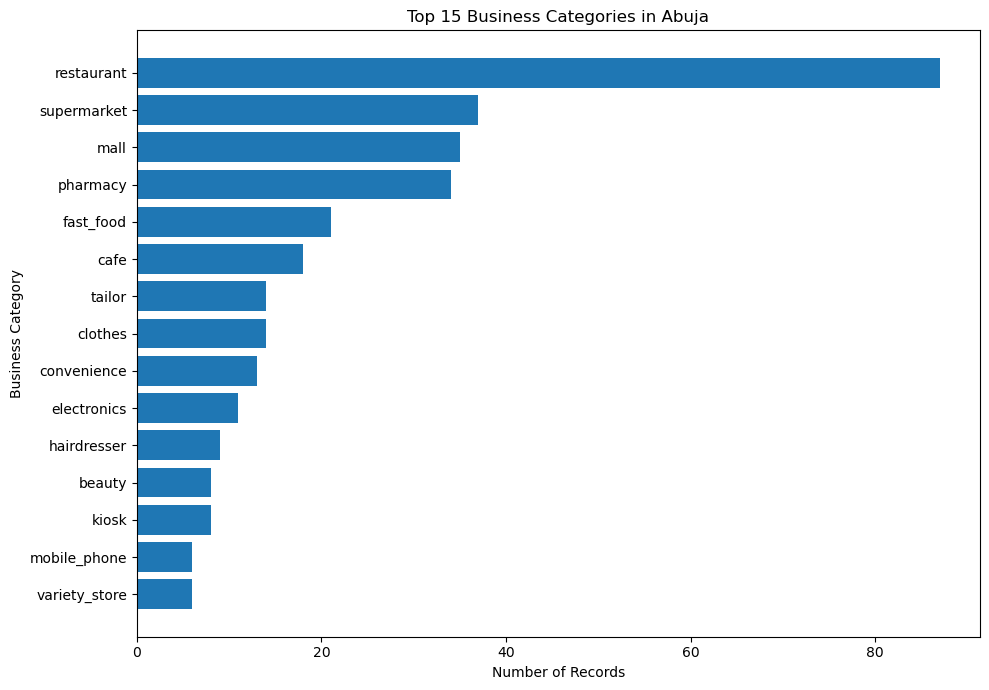

In [44]:
# Select the top 15 business categories

top_15_categories = category_counts.head(15)

# Create horizontal bar chart

plt.figure(figsize=(10, 7))

plt.barh(
    top_15_categories["Business_Category"],
    top_15_categories["Record_Count"]
)

plt.xlabel("Number of Records")
plt.ylabel("Business Category")
plt.title("Top 15 Business Categories in Abuja")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### 11.3 Business Category Proportions

This analysis calculates the percentage contribution of each business category to the total classified records. It helps identify which categories account for the largest share of the collected dataset.

In [45]:
# Calculate percentage contribution of each category

category_counts["Percentage"] = (
    category_counts["Record_Count"] / 
    category_counts["Record_Count"].sum()
) * 100

# Display the top 15 categories with their percentages

category_counts.head(15).round(2)

,Business_Category,Record_Count,Percentage
0,restaurant,87,22.37
1,supermarket,37,9.51
2,mall,35,9.00
3,pharmacy,34,8.74
4,fast_food,21,5.40
5,cafe,18,4.63
6,tailor,14,3.60
7,clothes,14,3.60
8,convenience,13,3.34
9,electronics,11,2.83


**Key Observation:**

Restaurants are the most frequently recorded business category, accounting for 22.37% of classified records. Supermarkets, malls and pharmacies follow. The four most represented categories account for approximately 49.62% of the classified dataset.

This distribution highlights the prominence of food services, retail outlets and pharmaceutical businesses within the selected study area.

### 11.4 Distribution of OpenStreetMap Object Types

This analysis examines the different OpenStreetMap object types returned during data extraction. It helps us understand how the collected business locations are represented geographically.

In [46]:
# Count the different OSM object types

object_type_counts = df["Object_Type"].value_counts()

object_type_counts

Object_Type
node        288
way         144
relation      1
Name: count, dtype: int64

### 11.5 OpenStreetMap Object Type Distribution

A bar chart is used to compare the number of records collected for each OpenStreetMap object type. This provides insight into how the extracted geographic features are represented.

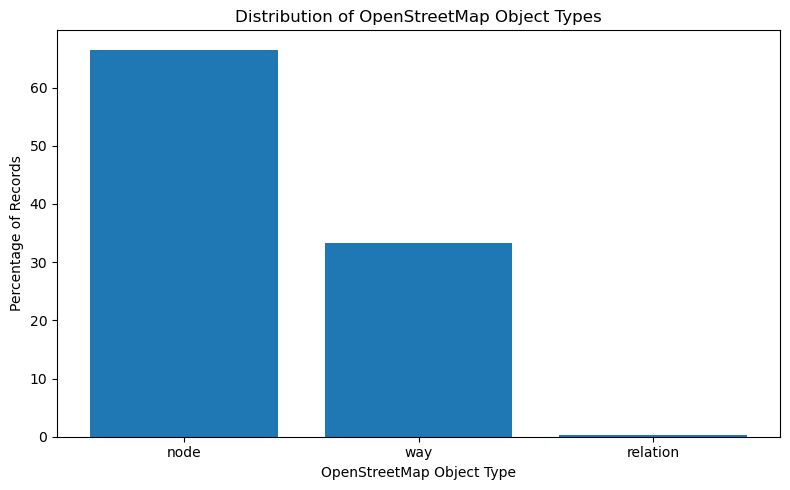

In [47]:
# Calculate object type percentages

object_type_percentage = (
    df["Object_Type"].value_counts(normalize=True) * 100
)

# Create visualization

plt.figure(figsize=(8, 5))

plt.bar(
    object_type_percentage.index,
    object_type_percentage.values
)

plt.xlabel("OpenStreetMap Object Type")
plt.ylabel("Percentage of Records")
plt.title("Distribution of OpenStreetMap Object Types")

plt.tight_layout()
plt.show()

**Key Observation:**

Nodes represent the largest proportion of collected OpenStreetMap objects, accounting for 66.51% of the dataset. Ways contribute 33.26%, while relations account for only 0.23%.

This indicates that the extracted dataset is predominantly composed of point-based geographic features.

### 11.6 Geographic Distribution of Business Records

This visualization uses latitude and longitude coordinates to examine the spatial distribution of collected business records within the selected Abuja study area. It helps identify areas with higher concentrations of mapped features.

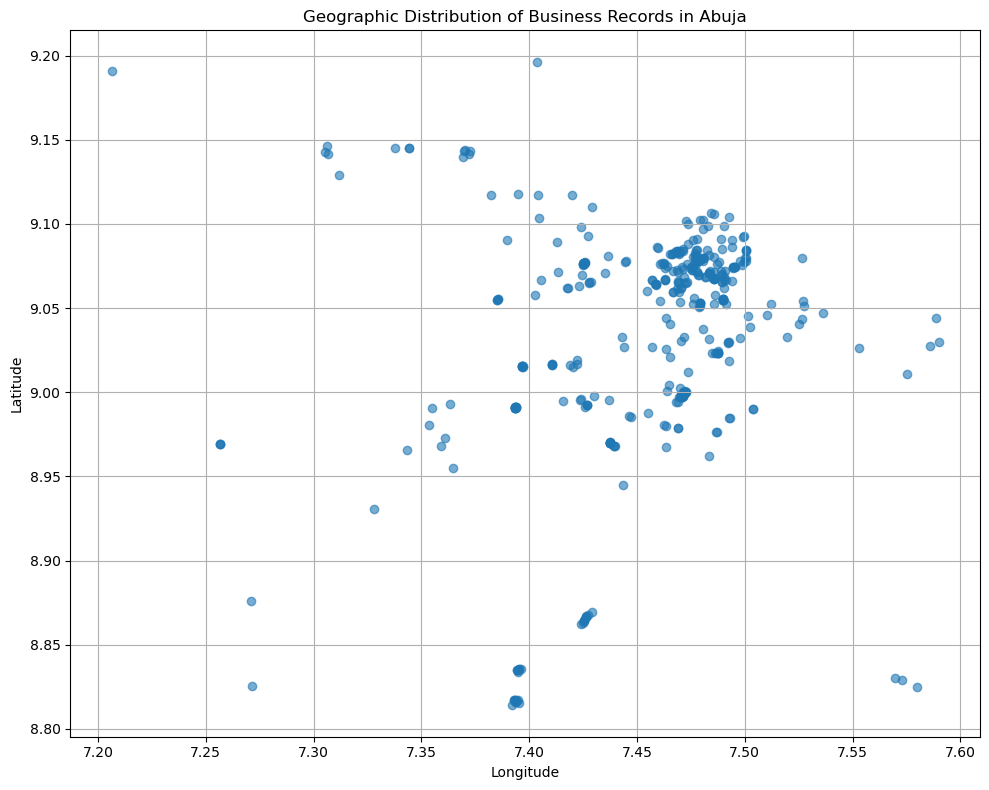

In [48]:
# Visualize geographic distribution

plt.figure(figsize=(10, 8))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    alpha=0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Business Records in Abuja")

plt.grid(True)
plt.tight_layout()
plt.show()

### 11.7 Geographic Concentration Analysis

The study area is divided into a 5 × 5 grid using latitude and longitude intervals. The number of business records within each grid cell is calculated to identify areas with higher concentrations of mapped features.

In [49]:
# Divide the study area into 5 geographic intervals

df["Latitude_Zone"] = pd.cut(
    df["Latitude"],
    bins=5,
    labels=False
)

df["Longitude_Zone"] = pd.cut(
    df["Longitude"],
    bins=5,
    labels=False
)

# Count records within each grid cell

geographic_distribution = pd.crosstab(
    df["Latitude_Zone"],
    df["Longitude_Zone"]
)

geographic_distribution

Longitude_Zone,0,1,2,3,4
Latitude_Zone,,,,,
0,2,0,29,0,3
1,0,2,1,2,0
2,3,3,37,102,7
3,0,0,40,183,5
4,1,7,6,0,0


### 11.8 Geographic Distribution by Classification Status

This analysis compares classified and unclassified records across geographic grid cells. It helps determine whether areas with high record concentrations are also areas with better business classification coverage.

In [50]:
# Compare classification status across geographic grid cells

geographic_status = pd.crosstab(
    [df["Latitude_Zone"], df["Longitude_Zone"]],
    df["Category_Status"]
)

geographic_status

Category_Status               Classified  Unclassified
Latitude_Zone Longitude_Zone                          
0             0                        2             0
              2                       29             0
              4                        3             0
1             1                        2             0
              2                        1             0
              3                        2             0
2             0                        3             0
              1                        3             0
              2                       37             0
              3                       59            43
              4                        7             0
3             2                       40             0
              3                      182             1
              4                        5             0
4             0                        1             0
              1                        7             0
              2                        6             0

In [51]:
# Reformat geographic classification results

geographic_status_clean = (
    geographic_status
    .reset_index()
    .fillna(0)
)

geographic_status_clean

Category_Status,Latitude_Zone,Longitude_Zone,Classified,Unclassified
0,0,0,2,0
1,0,2,29,0
2,0,4,3,0
3,1,1,2,0
4,1,2,1,0
5,1,3,2,0
6,2,0,3,0
7,2,1,3,0
8,2,2,37,0
9,2,3,59,43


### Geographic Distribution of Classified and Unclassified Records

The geographic comparison shows that unclassified records are heavily concentrated in Latitude Zone 2 and Longitude Zone 3, which contains 43 of the 44 unclassified records (97.7%). In contrast, most other grid cells contain only classified records.

This indicates that category information is not equally complete across the study area. The concentration may reflect differences in how business features were mapped or tagged in OpenStreetMap.

These findings should be interpreted cautiously because the grid zones are analytical divisions rather than official neighbourhood boundaries.

In [52]:
geographic_status_clean[["Classified", "Unclassified"]].sum()

Category_Status
Classified      389
Unclassified     44
dtype: int64

### Geographic Concentration Analysis

A geographic grid was used to examine the spatial distribution of mapped business-related records across the study area. The records were grouped into latitude and longitude zones to identify areas with higher concentrations.

This approach provides a simple overview of spatial clustering, although it does not represent official administrative or neighbourhood boundaries.

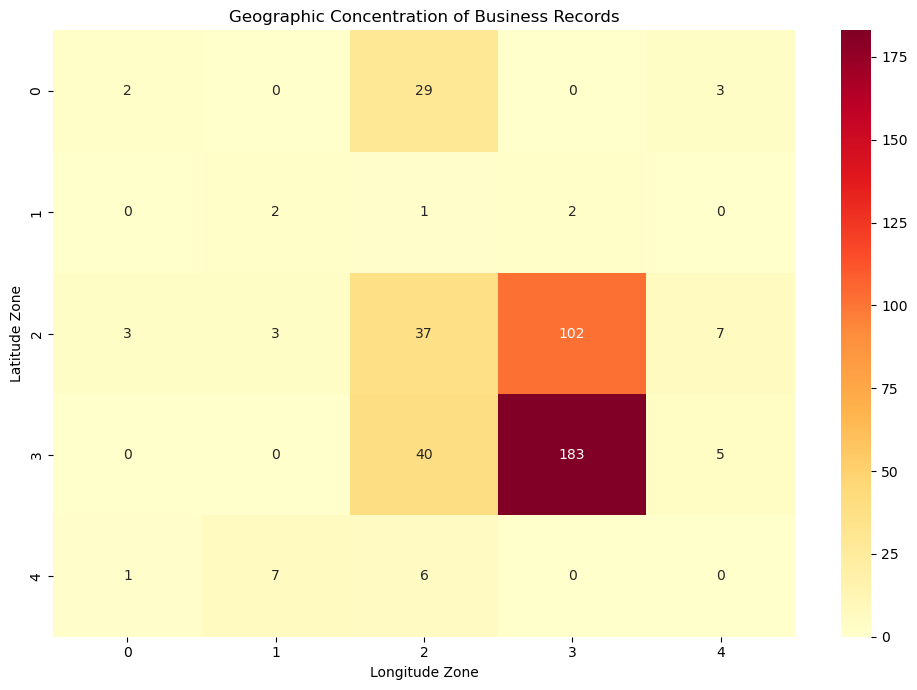

In [53]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    geographic_distribution,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Geographic Concentration of Business Records")
plt.xlabel("Longitude Zone")
plt.ylabel("Latitude Zone")
plt.tight_layout()
plt.show()

In [54]:
geographic_distribution.stack().sort_values(ascending=False).head(10)

Latitude_Zone  Longitude_Zone
3              3                 183
2              3                 102
3              2                  40
2              2                  37
0              2                  29
4              1                   7
2              4                   7
4              2                   6
3              4                   5
0              4                   3
dtype: int64

### Geographic Concentration Findings

The geographic grid analysis revealed that mapped business-related records are concentrated in a small number of grid cells. Latitude Zone 3, Longitude Zone 3 contained the highest number of records (183), followed by Latitude Zone 2, Longitude Zone 3 (102).

Together, these two grid cells account for approximately 65.8% of the 433 extracted records. This suggests an uneven spatial distribution within the selected study area.

The findings describe the distribution of available OpenStreetMap records and should not be interpreted as a complete representation of Abuja's retail market.

In [55]:
import folium

print("Folium version:", folium.__version__)

Folium version: 0.20.0


In [56]:
map_center = [
    df["Latitude"].mean(),
    df["Longitude"].mean()
]

map_center

[9.030675889838339, 7.453273397228638]

In [57]:
business_map = folium.Map(
    location=map_center,
    zoom_start=12,
    tiles="OpenStreetMap"
)

business_map

In [58]:
for _, row in df.iterrows():

    if pd.notna(row["Latitude"]) and pd.notna(row["Longitude"]):

        folium.Marker(
            location=[row["Latitude"], row["Longitude"]],
            popup=f"""
            <b>Name:</b> {row['Business_Name']}<br>
            <b>Category:</b> {row['Business_Category']}<br>
            <b>OSM ID:</b> {row['OSM_ID']}
            """
        ).add_to(business_map)

business_map

In [59]:
category_colors = {
    "restaurant": "red",
    "supermarket": "blue",
    "mall": "green",
    "pharmacy": "purple",
    "fast_food": "orange",
    "cafe": "darkred"
}

for _, row in df.iterrows():

    category = row["Business_Category"]

    color = category_colors.get(category, "gray")

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=5,
        color=color,
        fill=True,
        fill_opacity=0.7,
        popup=f"""
        <b>Name:</b> {row['Business_Name']}<br>
        <b>Category:</b> {category}<br>
        <b>OSM ID:</b> {row['OSM_ID']}
        """
    ).add_to(business_map)

business_map

In [60]:
business_map = folium.Map(
    location=map_center,
    zoom_start=12,
    tiles="OpenStreetMap"
)

In [61]:
categories_to_map = [
    "restaurant",
    "supermarket",
    "mall",
    "pharmacy",
    "fast_food",
    "cafe"
]

category_layers = {}

for category in categories_to_map:
    category_layers[category] = folium.FeatureGroup(
        name=category.title()
    )

In [62]:
for _, row in df.iterrows():

    category = row["Business_Category"]

    if category in category_layers:

        folium.CircleMarker(
            location=[row["Latitude"], row["Longitude"]],
            radius=5,
            color=category_colors.get(category, "gray"),
            fill=True,
            fill_opacity=0.7,
            popup=f"""
            <b>Name:</b> {row['Business_Name']}<br>
            <b>Category:</b> {category}<br>
            <b>OSM ID:</b> {row['OSM_ID']}
            """
        ).add_to(category_layers[category])

In [63]:
for layer in category_layers.values():
    layer.add_to(business_map)

folium.LayerControl().add_to(business_map)

business_map

In [64]:
df["Business_Category"].value_counts().head(6).sum()


232

In [65]:
other_layer = folium.FeatureGroup(name="Other Categories")

for _, row in df.iterrows():

    category = row["Business_Category"]

    if pd.notna(category) and category not in categories_to_map:

        folium.CircleMarker(
            location=[row["Latitude"], row["Longitude"]],
            radius=4,
            color="gray",
            fill=True,
            fill_opacity=0.6,
            popup=f"""
            <b>Name:</b> {row['Business_Name']}<br>
            <b>Category:</b> {category}<br>
            <b>OSM ID:</b> {row['OSM_ID']}
            """
        ).add_to(other_layer)

other_layer.add_to(business_map)

business_map

In [66]:
unclassified_layer = folium.FeatureGroup(
    name="Unclassified Records"
)

for _, row in df[df["Category_Status"] == "Unclassified"].iterrows():

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=4,
        color="black",
        fill=True,
        fill_color="black",
        fill_opacity=0.6,
        popup=f"""
        <b>Name:</b> {row['Business_Name']}<br>
        <b>Status:</b> Unclassified<br>
        <b>OSM ID:</b> {row['OSM_ID']}
        """
    ).add_to(unclassified_layer)

unclassified_layer.add_to(business_map)

folium.LayerControl().add_to(business_map)

business_map

In [67]:
df.to_csv(
    "abuja_retail_businesses_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [68]:
with open("abuja_retail_businesses_raw.json", "w", encoding="utf-8") as file:
    json.dump(data, file, ensure_ascii=False, indent=4)

print("Raw JSON data exported successfully!")

Raw JSON data exported successfully!


In [69]:
business_map.save("abuja_retail_business_map.html")

print("Interactive map exported successfully!")

Interactive map exported successfully!


## Project Conclusion

This project used the OpenStreetMap Overpass API to collect and analyse business-related location data within a selected geographic area of Abuja, Nigeria.

A total of 433 map elements were retrieved and transformed into a structured dataset containing 15 attributes, including business names, categories, contact information and geographic coordinates.

The data quality assessment identified missing business information, repeated business names and generic category tags. After cleaning and standardisation, 389 records had identifiable business categories, while 44 remained unclassified.

Exploratory analysis revealed that restaurants, supermarkets, malls and pharmacies were among the most frequently represented categories. Geographic analysis also showed that records were concentrated in a few grid cells within the study area.

An interactive map was developed using Folium to support geographic exploration and category-based filtering. The raw JSON data, cleaned CSV dataset and interactive HTML map were exported as project deliverables.

### Limitations

- The dataset represents OpenStreetMap records and may not include every operating business in the selected area.
- Missing and inconsistent tags affected data completeness.
- Repeated business names do not necessarily represent duplicate locations.
- The geographic analysis covers a pilot bounding box, not the entirety of Abuja or the FCT.
- The extracted records should not be treated as a verified census of active businesses.

Overall, the project demonstrates practical experience in API-based data extraction, JSON processing, data cleaning, exploratory data analysis and geographic data visualisation.